<a href="https://colab.research.google.com/github/linethr-tech/responsible-ai-mini-audit/blob/main/mini_responsible_ai_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
# Mini Responsible AI Audit — Credit Default Model

In [10]:
!pip install -q ucimlrepo fairlearn shap

import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

In [11]:
data = fetch_ucirepo(id=350)  # Default of Credit Card Clients
X = data.data.features.copy()
y = data.data.targets.iloc[:, 0]

names = ["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE",
         "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
         "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
         "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"]
X.columns = names

sex = X["SEX"].map({1: "Male", 2: "Female"})
print(X.shape)
print(y.value_counts(normalize=True))

(30000, 23)
Y
0    0.7788
1    0.2212
Name: proportion, dtype: float64


In [12]:
# First finding (the classes are imbalanced). 0,000 rows × 23 columns, and about 22% defaults

In [13]:
# Train the model:I used a gradient boosting model that is strong enough on tabular data and fast to explain with SHAP plot.

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, recall_score, classification_report

X_train, X_test, y_train, y_test, sex_train, sex_test = train_test_split(
    X, y, sex, test_size=0.3, stratify=y, random_state=42)

model = HistGradientBoostingClassifier(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("ROC AUC:", round(roc_auc_score(y_test, y_proba), 3))
print("Recall (defaults caught):", round(recall_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred))

Accuracy: 0.818
ROC AUC: 0.777
Recall (defaults caught): 0.364
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      7009
           1       0.66      0.36      0.47      1991

    accuracy                           0.82      9000
   macro avg       0.75      0.66      0.68      9000
weighted avg       0.80      0.82      0.80      9000



In [15]:
# The accuracy is around 0.82 and AUC around 0.78. Recall is low (roughly 0.35–0.40): the model misses most defaults. The accuracy looks good only because of the imbalance, and it's a point I'll reuse in the model card.

In [16]:
# Does the model flag men and women as defaulters at different rates, and does it catch real defaults equally well for both?

        accuracy  recall  selection_rate
SEX                                     
Female     0.829   0.378           0.120
Male       0.801   0.346           0.126
Demographic parity difference: 0.006
Equalized odds difference: 0.032


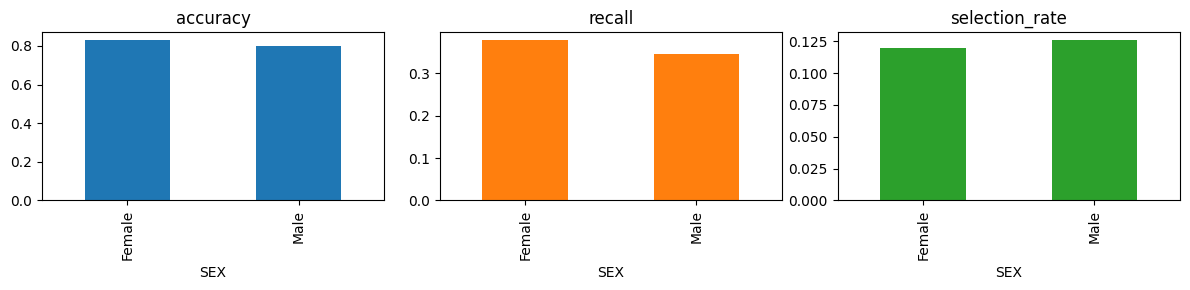

In [17]:
from fairlearn.metrics import (MetricFrame, selection_rate,
    demographic_parity_difference, equalized_odds_difference)

mf = MetricFrame(
    metrics={"accuracy": accuracy_score,
             "recall": recall_score,
             "selection_rate": selection_rate},
    y_true=y_test, y_pred=y_pred, sensitive_features=sex_test)

print(mf.by_group.round(3))
print("Demographic parity difference:",
      round(demographic_parity_difference(y_test, y_pred, sensitive_features=sex_test), 3))
print("Equalized odds difference:",
      round(equalized_odds_difference(y_test, y_pred, sensitive_features=sex_test), 3))

mf.by_group.plot.bar(subplots=True, layout=(1, 3), figsize=(12, 3), legend=False)
plt.tight_layout()
plt.savefig("fairness_by_gender.png", dpi=150)
plt.show()

In [18]:
# The model shows no meaningful gender disparity: selection rates differ by 0.6 percentage points (demographic parity difference 0.006) and the equalized odds difference is 0.032. Recall is slightly lower for men (34.6% vs 37.8%). The main risk is low recall for both groups, since the model misses most actual defaults. Gender is the only sensitive attribute checked; proxy effects through other features are not assessed here.

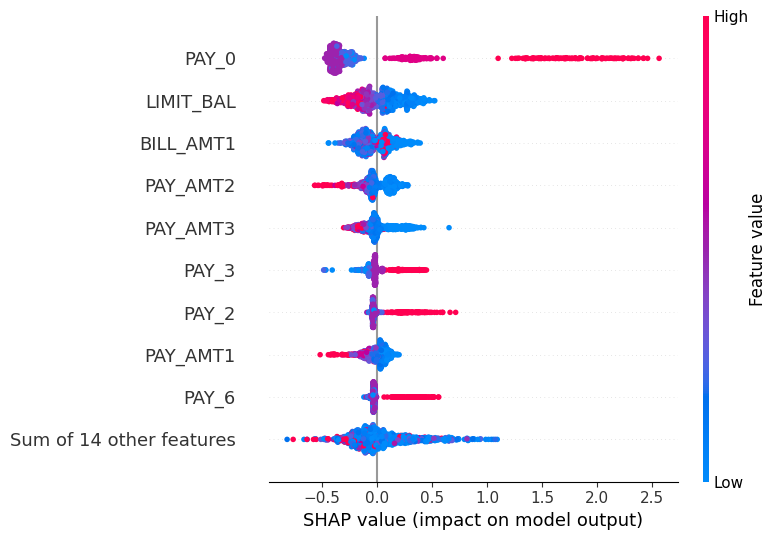

In [19]:
import shap

X_sample = X_test.sample(1000, random_state=42)
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_sample)

shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.tight_layout()
plt.savefig("shap_beeswarm.png", dpi=150)
plt.show()

In [20]:
# SHAP shows the model relies mainly on recent repayment behaviour (PAY_0) and credit limit (LIMIT_BAL). SEX does not appear among the top 9 features, consistent with the small fairness gaps in Step 3. However, low direct use of a sensitive attribute does not rule out proxy bias, e.g. through credit limit.

In [21]:
# The limits are different by gender?
print(X.groupby(sex)["LIMIT_BAL"].mean().round(0))

SEX
Female    170086.0
Male      163520.0
Name: LIMIT_BAL, dtype: float64


In [22]:
# Average credit limit is similar across genders (Female: 170,086 NT$; Male: 163,520 NT$, ~4% difference), so LIMIT_BAL is unlikely to act as a strong gender proxy. Only means were compared; distributional differences were not assessed.